# Трек 1. Агент в классической среде
Исследовательская задача
Выясните, от чего зависит качество, устойчивость или эффективность RL-агента в стандартной среде.

### 1. Исследовательский вопрос.
Среда gymnasium Lunalander-V3. При фиксированном бюджете взаимодействий: зависит ли величина падения качества агента при оценке в условии с ветром(шумом) не встречавшемся при обучении, от того, подвергался ли агент ветру во время обучения? То есть, покажет ли агент, обученный с ветром(enable_wind=True), меньший разрыв при оценке с ветром, чем агент, обученные без ветра.

### 2. Гипотеза
Базовое условие (обучение без ветра): при оценке с ветром средняя награда падает более чем на 40% относительно оценки без ветра. Экспериментальное условие (обучение с ветром, тот же бюджет): при той же оценке с ветром падение менее 20%.
Причина: обучение с ветром вынуждает политику выучить компенсаторные управляющие действия и стать устойчивой к возмущениям динамики. Политика, обученная без ветра, опирается на точную детерминированную динамику, и боковая сила ветра напрямую ломает отслеживание траектории.
Рискованность: при слишком слабом ветре различие может быть незначимым, при слишком сильно оба агента рушатся, и разница скрывается. Нужен предварительный подбор wind_power, при котором базовое условие заметно деградирует, а экспериментальное ещё обучаемо.
### 3. Метрика
Основная: относительный разрыв gap=(R_calm-R_wind)/|R_calm|, где R_calm – средняя награда при оценке с enable_wind=False (100 эпизодов), R_wind – при enable_wind=True с измененым wind_power от 0 до 20 шаг 5 wind_power (100 эпизодов, на каждую силу ветроу).



### 4. План сравнения
|---|Базовое условие|Экспериментальное условие|
|---|---|---|
|enable_wind при обучении| False| True|
|wind_power при обучении| не применимо| фиксирован|
|Алгоритм|Dueling DQN (SB3, MlpPolicy)| Dueling DQN (SB3, MlpPolicy) |
|Бюджет обучения|500 000 шагов среды|500 000 шагов среды|
|Оценка R_calm|enable_wind=False| enable_wind=False|
|Оценка R_wind|enable_wind=True, wind_power=[5,10,15,20]|enable_wind=True,wind_power=[5,10,15,20]|

Меняется ровно один фактор — диапазон стартов при обучении. Бюджет, алгоритм, seed, процедура оценки совпадают.

In [249]:
import random
import numpy as np
import psutil
import torch
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from tqdm import trange
from IPython.display import clear_output
from pathlib import Path
from gymnasium.wrappers import RecordVideo
from IPython.display import Video, display
import copy
import sys
%matplotlib inline

In [250]:
print(sys.version)

3.13.13 (main, Apr  7 2026, 20:48:32) [MSC v.1944 64 bit (AMD64)]


In [251]:
if not torch.cuda.is_available():
    # Для маленькой MLP многопоточные накладные расходы на CPU выше выигрыша.
    torch.set_num_threads(1)


def linear_decay(start: float, final: float, step: int, decay_steps: int) -> float:
    fraction = min(max(step / decay_steps, 0.0), 1.0)
    return start + fraction * (final - start)


def is_enough_ram(min_available_gb: float = 0.1) -> bool:
    return psutil.virtual_memory().available >= min_available_gb * 2**30

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# те, у кого есть GPU, но считают несправедливым его использовать, могут раскомментировать:
# device = torch.device('cpu')
device

device(type='cuda')

# Определение агента среды

In [252]:
class DQNAgent(nn.Module):
    def __init__(self, state_shape, n_actions, epsilon=0):
        super().__init__()
        self.epsilon = epsilon
        self.n_actions = n_actions
        self.state_shape = state_shape
        assert len(state_shape) == 1
        state_dim = state_shape[0]

        
        self.fc1=nn.Linear(state_dim,64)
        self.fc2=nn.Linear(64,64)
        self.out=nn.Linear(64,n_actions)


    def forward(self, state_t):
        """Возвращает Q-значения формы [batch_size, n_actions]."""
        
        x=torch.relu(self.fc1(state_t))
        x=torch.relu(self.fc2(x))
        qvalues=self.out(x)
 

        if torch.is_grad_enabled():
            assert qvalues.requires_grad, "qvalues must carry gradients in grad mode"
        assert qvalues.shape == (state_t.shape[0], self.n_actions)
        return qvalues

    @torch.no_grad()
    def get_qvalues(self, states):
        """Вычисляет Q-значения для numpy-массива состояний."""
        model_device = next(self.parameters()).device
        states = torch.as_tensor(np.asarray(states), device=model_device, dtype=torch.float32)
        
        qvalues=self.forward(states)

        return qvalues.cpu().numpy()

    def sample_actions(self, qvalues):
        """Выбирает действия по epsilon-greedy политике."""
        batch_size, n_actions = qvalues.shape
        
        
        best_actions=np.argmax(qvalues,axis=-1)
        random_actions=np.random.choice(n_actions,size=batch_size)

        #Создаём маску масив, которая применяется на весь batch, где тру будем брать лучшее действие, где false случайное действие
        should_explorer=np.random.uniform(0,1,size=batch_size)<=self.epsilon
     
        #Применяем маску
        actions=np.where(should_explorer,random_actions,best_actions)

        return actions




In [253]:

class DuelingDQNHead(nn.Module):
    def __init__(self, input_dim, n_actions):
        super().__init__()
        
       
        self.fc1_dual=nn.Linear(input_dim,128)
        self.fc2_dual=nn.Linear(128,128)
        #self.out=nn.Linear(64,n_actions)
                      
        self.advantage_stream =nn.Linear(128,n_actions)
        self.value_stream = nn.Linear(128,1)


    def forward(self, x):
        
        x=torch.relu(self.fc1_dual(x))
        x=torch.relu(self.fc2_dual(x))
        value=self.value_stream(x)
        advantage=self.advantage_stream(x)
        qvalues=value+(advantage-advantage.mean(dim=1,keepdim=True))

        return qvalues


In [254]:

class DuelingDQN(nn.Module):
    def __init__(self, state_shape, n_actions):
        super().__init__()
        
        state_dim=state_shape[0]
        self.feature_extractor=nn.Sequential(nn.Linear(state_dim,64),nn.ReLU(),)
        self.dueling_head=DuelingDQNHead(64,n_actions)


    def forward(self, x):
        return self.dueling_head(self.feature_extractor(x))


In [255]:

class DuelingDQNAgent(DQNAgent):
    def __init__(self, state_shape, n_actions, epsilon=0):
        nn.Module.__init__(self)
        self.epsilon = epsilon
        self.n_actions = n_actions
        self.state_shape = state_shape
        
        self.network=DuelingDQN(state_shape,n_actions)
    def forward(self, state_t):
       return self.network(state_t)    

### Функция потерь 

In [256]:
def compute_td_loss_double(states, actions, rewards, next_states, is_done,
                           agent, target_network, gamma=0.99,
                           loss_kind="mse", check_shapes=False, device=device):
    states = torch.as_tensor(states, dtype=torch.float32, device=device)
    actions = torch.as_tensor(actions, dtype=torch.int64, device=device)
    rewards = torch.as_tensor(rewards, dtype=torch.float32, device=device)
    next_states = torch.as_tensor(next_states, dtype=torch.float32, device=device)
    is_done = torch.as_tensor(is_done, dtype=torch.bool, device=device)

    predicted_qvalues = agent(states)
    ### ВАШ КОД
    # Значения для реальны выполненых действий
    predictions = predicted_qvalues.gather(1, actions.unsqueeze(1)).squeeze(1)   
  

    with torch.no_grad():
            # Сеть Agent выбирает действия 
            next_qvalues_agent = agent(next_states)
            next_act = next_qvalues_agent.argmax(dim=1,keepdim=True)
            #Для оценки ценности выбранного действия используется целевая сеть
            next_qvalues_target=target_network(next_states)
            next_values=next_qvalues_target.gather(1,next_act).squeeze(1)

                 
            targets = (rewards
                       + gamma * next_values * (~is_done).float()
                   )
    if loss_kind=='mse':
        loss=nn.MSELoss()(predictions,targets)
    if loss_kind=='huber':
        loss=nn.HuberLoss()(predictions,targets)
    
    ### ВАШ КОД ЗАКОНЧИЛСЯ

    if check_shapes:
        assert predictions.shape == rewards.shape
        assert targets.shape == rewards.shape
        assert not targets.requires_grad
    return loss

### Буфер повторов

Интерфейс довольно прост:
* `exp_replay.add(obs, act, rw, next_obs, done)` - сохраняет кортеж (s,a,r,s',done) в буфер
* `exp_replay.sample(batch_size)` - возвращает наблюдения, действия, награды, следующие наблюдения и флаги завершения эпизода для `batch_size` случайных образцов.
* `len(exp_replay)` - возвращает количество элементов, хранящихся в буфере воспроизведения.

In [257]:
class ReplayBuffer(object):
    def __init__(self, size):
        """Создаёт буфер воспроизведения.
        Параметры
        ----------
        size: int
            Максимальное количество переходов, которые можно хранить в буфере.
            При переполнении буфера старые записи удаляются.
        """
        self._storage = []
        self._maxsize = size
        self._next_idx = 0

    def __len__(self):
        return len(self._storage)

    def add(self, obs_t, action, reward, obs_tp1, done):
        data = (obs_t, action, reward, obs_tp1, done)

        if self._next_idx >= len(self._storage):
            self._storage.append(data)
        else:
            self._storage[self._next_idx] = data
        self._next_idx = (self._next_idx + 1) % self._maxsize

    def _encode_sample(self, idxes):
        obses_t, actions, rewards, obses_tp1, dones = [], [], [], [], []
        for i in idxes:
            data = self._storage[i]
            obs_t, action, reward, obs_tp1, done = data
            obses_t.append(np.asarray(obs_t))
            actions.append(np.asarray(action))
            rewards.append(reward)
            obses_tp1.append(np.asarray(obs_tp1))
            dones.append(done)
        return (
            np.array(obses_t),
            np.array(actions),
            np.array(rewards),
            np.array(obses_tp1),
            np.array(dones),
        )

    def sample(self, batch_size):
        """Выбирает случайную партию переходов из буфера.
        Параметры
        ----------
        batch_size: int
            Сколько переходов нужно выбрать.
        Возвращает
        -------
        obs_batch: np.array
            партия наблюдений
        act_batch: np.array
            партия действий, выполненных в состоянии obs_batch
        rew_batch: np.array
            вознаграждения, полученные в результате выполнения act_batch
        next_obs_batch: np.array
            следующие наблюдения после выполнения act_batch
        done_mask: np.array
            done_mask[i] = 1, если выполнение act_batch[i] привело к завершению эпизода,
            и 0 в противном случае.
        """
        idxes = [random.randint(0, len(self._storage) - 1) for _ in range(batch_size)]
        return self._encode_sample(idxes)

### Взаимодействие со средой: `play_and_record`

In [258]:
def play_and_record(initial_state, agent, env, exp_replay, n_steps=1):
    """Делает ровно n_steps взаимодействий и записывает переходы в replay.

    Среда сбрасывается и при terminated, и при truncated. В поле done хранится
    только terminated: ограничение времени не должно обнулять bootstrap-цель.
    """
    state = initial_state
    sum_rewards = 0.0

    ### ВАШ КОД
    for n in range(n_steps):
      qvalues = agent.get_qvalues([state])
      action = agent.sample_actions(qvalues)[0]
      #Получаем информацию от среды
      next_state, reward, terminated, truncated,_ = env.step(action)
      sum_rewards += reward
      #Записываем состояние
      exp_replay.add(state,action,reward,next_state,terminated)
      if terminated or truncated:
        state,_=env.reset()
      else:
         state=next_state
    ### ВАШ КОД ЗАКОНЧИЛСЯ

    return sum_rewards, state

# Функция оценки

In [259]:
LUNAR_MAX_EPISODE_STEPS=1000

In [260]:
def evaluate(env, agent, n_games=1, greedy=False, t_max=LUNAR_MAX_EPISODE_STEPS,
             seed=None, return_rewards=False):
    """Играет независимые эпизоды и возвращает среднюю награду или весь массив.

    При заданном seed эпизоды получают seed, seed + 1, ... и поэтому используют
    воспроизводимые, но различные начальные состояния.
    """
    rewards = []
    for game_idx in range(n_games):
        episode_seed = None if seed is None else seed + game_idx
        state, _ = env.reset(seed=episode_seed)
        total_reward = 0.0
        for _ in range(t_max):
            qvalues = agent.get_qvalues([state])
            action = qvalues.argmax(axis=-1)[0] if greedy else agent.sample_actions(qvalues)[0]
            state, reward, terminated, truncated, _ = env.step(action)
            total_reward += reward
            if terminated or truncated:
                break
        rewards.append(total_reward)

    rewards = np.asarray(rewards, dtype=np.float32)
    return rewards if return_rewards else float(rewards.mean())

# Определение среды LunarLander без ветра

In [261]:


LUNAR_ENV_NAME = "LunarLander-v3"
LUNAR_MAX_EPISODE_STEPS = 1000


def make_lunar_env(render_mode=None,wind_power=0):
    return gym.make(LUNAR_ENV_NAME, wind_power=wind_power,continuous=False, render_mode=render_mode,enable_wind=False)

def make_lunar_env_wind(render_mode=None,wind_power=10):
    return gym.make(LUNAR_ENV_NAME, wind_power=wind_power , continuous=False, render_mode=render_mode,enable_wind=True)

env=gym.make("LunarLander-v3")

lunar_probe_env = make_lunar_env()
lunar_state_shape = lunar_probe_env.observation_space.shape
lunar_n_actions = lunar_probe_env.action_space.n
assert lunar_state_shape == (8,)
assert lunar_n_actions == 4
print("Наблюдение:", lunar_state_shape, "действий:", lunar_n_actions)
lunar_probe_env.close()


lunar_probe_env = make_lunar_env_wind()
lunar_state_shape = lunar_probe_env.observation_space.shape
lunar_n_actions = lunar_probe_env.action_space.n
assert lunar_state_shape == (8,)
assert lunar_n_actions == 4
print("Наблюдение:", lunar_state_shape, "действий:", lunar_n_actions)
lunar_probe_env.close()

Наблюдение: (8,) действий: 4
Наблюдение: (8,) действий: 4


# Гиперпараметры обучения

# Инициализация сети и буфера

In [ ]:
### ВАШ КОД
lunar_seed = 42
lunar_replay_size = 150_000
lunar_initial_fill = 10_000
lunar_collect_steps = 100
lunar_batch_size = 256
lunar_total_steps = 500_000
lunar_decay_steps = 60_000
lunar_learning_rate = 1e-3
lunar_init_epsilon = 1.0
lunar_final_epsilon = 0.01
lunar_target_update_freq = 1000
lunar_eval_freq = 5000
lunar_loss_freq = 100
lunar_max_grad_norm = 10.0
lunar_validation_n_games = 20
lunar_validation_seed = 10_000
lunar_validation_std_penalty = 0.25
lunar_validation_reward_threshold = 250.0
lunar_validation_p10_threshold = 150.0
lunar_required_strong_evaluations = 3


random.seed(lunar_seed)
np.random.seed(lunar_seed)
torch.manual_seed(lunar_seed)


lunar_train_dueling = True
lunar_reinitialize_network = True
lunar_loss_kind = "huber"  # допустимы "huber" и "mse"


lunar_agent_class = DuelingDQNAgent if lunar_train_dueling else DQNAgent
lunar_agent = lunar_agent_class(
    lunar_state_shape, lunar_n_actions, epsilon=lunar_init_epsilon).to(device)
lunar_target = lunar_agent_class(
    lunar_state_shape, lunar_n_actions, epsilon=0.0
).to(device)


def reset_trainable_layer(module):
    if hasattr(module, "reset_parameters"):
        module.reset_parameters()


if lunar_reinitialize_network:
    lunar_agent.apply(reset_trainable_layer)
lunar_target.load_state_dict(lunar_agent.state_dict())
lunar_optimizer = torch.optim.Adam(
    lunar_agent.parameters(), lr=lunar_learning_rate
)

lunar_replay = ReplayBuffer(lunar_replay_size)
lunar_fill_env = make_lunar_env()
lunar_state, _ = lunar_fill_env.reset(seed=lunar_seed)
while len(lunar_replay) < lunar_initial_fill:
    _, lunar_state = play_and_record(
        lunar_state, lunar_agent, lunar_fill_env, lunar_replay,
        n_steps=lunar_collect_steps,
    )
lunar_fill_env.close()
print("Размер LunarLander replay buffer:", len(lunar_replay))

Размер LunarLander replay buffer: 10000


In [263]:

lunar_eval_steps, lunar_rewards = [], []
lunar_reward_stds, lunar_reward_p10 = [], []
lunar_losses, lunar_loss_steps = [], []
lunar_grad_norms, lunar_initial_values = [], []
lunar_best_selection = -np.inf
lunar_best_mean = -np.inf
lunar_best_std = np.inf
lunar_best_p10 = -np.inf
lunar_best_step = 0
lunar_best_state = copy.deepcopy(lunar_agent.state_dict())
lunar_strong_streak = 0

# Цикл обучения


In [264]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Используем устройство: {device}")

lunar_agent.to(device)
lunar_target.to(device)



Используем устройство: cuda


DuelingDQNAgent(
  (network): DuelingDQN(
    (feature_extractor): Sequential(
      (0): Linear(in_features=8, out_features=64, bias=True)
      (1): ReLU()
    )
    (dueling_head): DuelingDQNHead(
      (fc1_dual): Linear(in_features=64, out_features=128, bias=True)
      (fc2_dual): Linear(in_features=128, out_features=128, bias=True)
      (advantage_stream): Linear(in_features=128, out_features=4, bias=True)
      (value_stream): Linear(in_features=128, out_features=1, bias=True)
    )
  )
)

In [265]:
lunar_eval_steps, lunar_rewards = [], []
lunar_reward_stds, lunar_reward_p10 = [], []
lunar_losses, lunar_loss_steps = [], []
lunar_grad_norms, lunar_initial_values = [], []
lunar_best_selection = -np.inf
lunar_best_mean = -np.inf
lunar_best_std = np.inf
lunar_best_p10 = -np.inf
lunar_best_step = 0
lunar_best_state = copy.deepcopy(lunar_agent.state_dict())
lunar_strong_streak = 0

lunar_train_env = make_lunar_env()
lunar_state, _ = lunar_train_env.reset(seed=lunar_seed + 1)
for lunar_step in trange(1, lunar_total_steps + 1):
    lunar_agent.epsilon = linear_decay(
        lunar_init_epsilon, lunar_final_epsilon,
        lunar_step, lunar_decay_steps,
    )
    _, lunar_state = play_and_record(
        lunar_state, lunar_agent, lunar_train_env, lunar_replay, n_steps=1
    )

    ### ВАШ КОД
    lunar_batch =lunar_replay.sample(lunar_batch_size)
    lunar_loss = compute_td_loss_double(*lunar_batch,lunar_agent,lunar_target,loss_kind=lunar_loss_kind)
    ### ВАШ КОД ЗАКОНЧИЛСЯ

    lunar_optimizer.zero_grad(set_to_none=True)
    lunar_loss.backward()
    lunar_grad_norm = nn.utils.clip_grad_norm_(
        lunar_agent.parameters(), lunar_max_grad_norm
    )
    lunar_optimizer.step()

    if lunar_step % lunar_loss_freq == 0:
        lunar_loss_steps.append(lunar_step)
        lunar_losses.append(float(lunar_loss.detach().cpu()))
        lunar_grad_norms.append(float(lunar_grad_norm))

    if lunar_step % lunar_target_update_freq == 0:
        ### ВАШ КОД
        lunar_target.load_state_dict(lunar_agent.state_dict())
        ### ВАШ КОД ЗАКОНЧИЛСЯ

    if lunar_step % lunar_eval_freq == 0:
        current_seed = lunar_validation_seed + lunar_step
        lunar_eval_env = make_lunar_env()
        scores = evaluate(
            lunar_eval_env,
            lunar_agent,
            n_games=lunar_validation_n_games,
            greedy=True,
            t_max=LUNAR_MAX_EPISODE_STEPS,
            seed=current_seed,
            return_rewards=True,
        )
        lunar_eval_env.close()
        mean_score = float(scores.mean())
        std_score = float(scores.std())
        p10_score = float(np.percentile(scores, 10))
        selection_score = mean_score - lunar_validation_std_penalty * std_score

        probe_env = make_lunar_env()
        initial_state = probe_env.reset(seed=20_000 + lunar_step)[0]
        lunar_initial_values.append(
            float(lunar_agent.get_qvalues([initial_state]).max())
        )
        probe_env.close()

        lunar_eval_steps.append(lunar_step)
        lunar_rewards.append(mean_score)
        lunar_reward_stds.append(std_score)
        lunar_reward_p10.append(p10_score)

        if selection_score > lunar_best_selection:
            lunar_best_selection = selection_score
            lunar_best_mean = mean_score
            lunar_best_std = std_score
            lunar_best_p10 = p10_score
            lunar_best_step = lunar_step
            lunar_best_state = copy.deepcopy(lunar_agent.state_dict())

        is_strong = (
            mean_score >= lunar_validation_reward_threshold
            and p10_score >= lunar_validation_p10_threshold
        )
        lunar_strong_streak = lunar_strong_streak + 1 if is_strong else 0
        clear_output(True)
        print(
            f"step={lunar_step}, validation={mean_score:.1f}±{std_score:.1f}, "
            f"p10={p10_score:.1f}, best={lunar_best_mean:.1f}±{lunar_best_std:.1f}"
        )
       

lunar_train_env.close()
lunar_agent.load_state_dict(lunar_best_state)
lunar_target.load_state_dict(lunar_best_state)
print(
    f"Восстановлен checkpoint: step={lunar_best_step}, "
    f"validation={lunar_best_mean:.1f}±{lunar_best_std:.1f}, "
    f"p10={lunar_best_p10:.1f}"
)

100%|██████████| 500000/500000 [28:56<00:00, 288.00it/s]

step=500000, validation=-906.6±810.6, p10=-1903.7, best=250.7±36.8
Восстановлен checkpoint: step=155000, validation=250.7±36.8, p10=227.1


Финал: mean=264.1, std=32.4, median=269.4, p10=232.2, min=181.1, max=316.3
Доля эпизодов >= 200: 93.3%


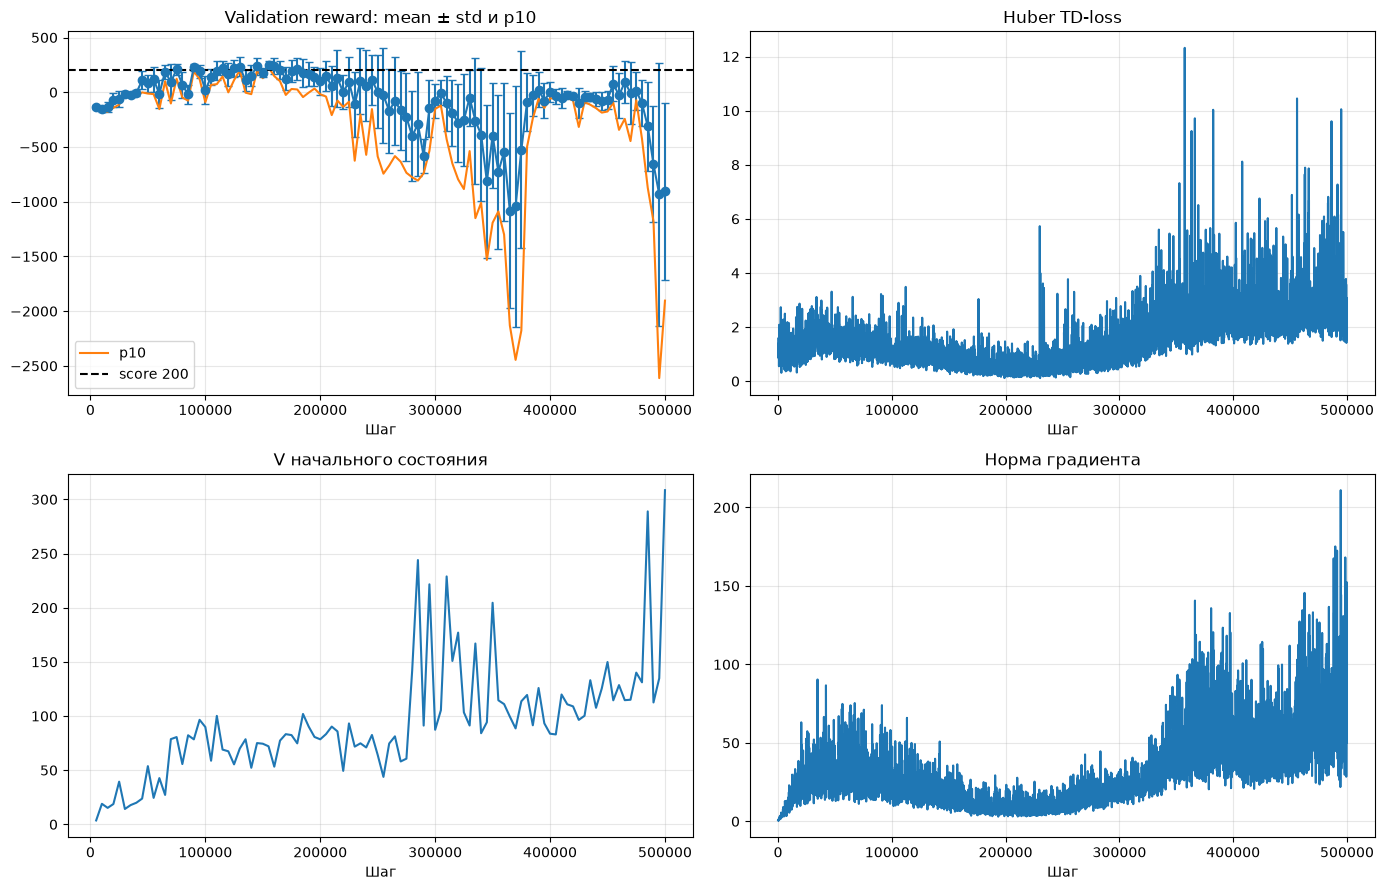

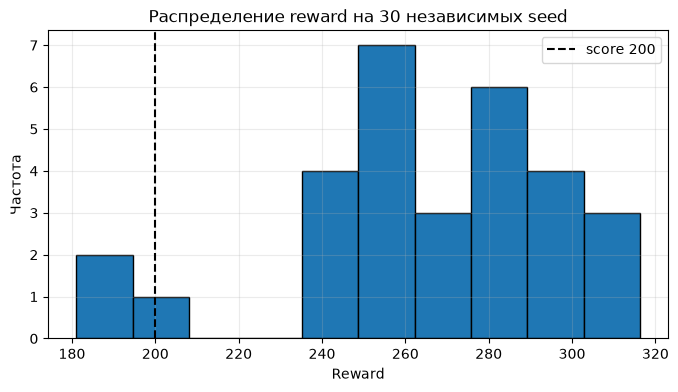

In [266]:
### ВАШ КОД
lunar_final_n_games = 30
lunar_final_seed = 42_000
lunar_score_threshold = 200.0
### ВАШ КОД ЗАКОНЧИЛСЯ

lunar_final_env = make_lunar_env()
lunar_final_scores = evaluate(
    lunar_final_env,
    lunar_agent,
    n_games=lunar_final_n_games,
    greedy=True,
    t_max=LUNAR_MAX_EPISODE_STEPS,
    seed=lunar_final_seed,
    return_rewards=True,
)
lunar_final_env.close()
print(
    f"Финал: mean={lunar_final_scores.mean():.1f}, "
    f"std={lunar_final_scores.std():.1f}, "
    f"median={np.median(lunar_final_scores):.1f}, "
    f"p10={np.percentile(lunar_final_scores, 10):.1f}, "
    f"min={lunar_final_scores.min():.1f}, max={lunar_final_scores.max():.1f}"
)
print(
    f"Доля эпизодов >= {lunar_score_threshold:.0f}: "
    f"{(lunar_final_scores >= lunar_score_threshold).mean():.1%}"
)
if lunar_final_scores.mean() < lunar_score_threshold:
    print(
        "Порог 200 пока не достигнут: Run All продолжается, чтобы графики "
        "помогли диагностировать обучение. Баллы за устойчивое решение требуют "
        "mean >= 200 на этих независимых seed."
    )

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes[0, 0].errorbar(
    lunar_eval_steps, lunar_rewards, yerr=lunar_reward_stds,
    marker="o", capsize=3,
)
axes[0, 0].plot(lunar_eval_steps, lunar_reward_p10, label="p10")
axes[0, 0].axhline(200, color="black", linestyle="--", label="score 200")
axes[0, 0].set(title="Validation reward: mean ± std и p10", xlabel="Шаг")
axes[0, 0].legend()
axes[0, 1].plot(lunar_loss_steps, lunar_losses)
axes[0, 1].set(title="Huber TD-loss", xlabel="Шаг")
axes[1, 0].plot(lunar_eval_steps, lunar_initial_values)
axes[1, 0].set(title="V начального состояния", xlabel="Шаг")
axes[1, 1].plot(lunar_loss_steps, lunar_grad_norms)
axes[1, 1].set(title="Норма градиента", xlabel="Шаг")
for ax in axes.flat:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
plt.close(fig)

plt.figure(figsize=(8, 4))
plt.hist(lunar_final_scores, bins=10, edgecolor="black")
plt.axvline(200, color="black", linestyle="--", label="score 200")
plt.title("Распределение reward на 30 независимых seed")
plt.xlabel("Reward")
plt.ylabel("Частота")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

In [267]:
MAX_EPISODE_STEPS = 1000

In [ ]:

lunar_video_seed = 90_001
lunar_video_folder = Path("videos_lunarlander")


lunar_video_env = RecordVideo(
    make_lunar_env(render_mode="rgb_array"),
    video_folder=str(lunar_video_folder),
    episode_trigger=lambda episode_number: episode_number == 0,
    name_prefix="final-lunarlander",
    disable_logger=True,
)
lunar_video_score = evaluate(
    lunar_video_env,
    lunar_agent,
    n_games=1,
    greedy=True,
    t_max=LUNAR_MAX_EPISODE_STEPS,
    seed=lunar_video_seed,
)
lunar_video_env.close()
lunar_video_paths = sorted(
    lunar_video_folder.glob("final-lunarlander*.mp4"),
    key=lambda path: path.stat().st_mtime,
)
assert lunar_video_paths, "Видео LunarLander не было создано"
print(f"Reward финального видео LunarLander: {lunar_video_score:.1f}")
display(Video(str(lunar_video_paths[-1]), embed=True))

c:\Users\Andrey\virtualEnvPython\RLenv\RLvenv\Lib\site-packages\gymnasium\wrappers\rendering.py:298: UserWarning: WARN: Overwriting existing videos at c:\git\RL_TRACK_SW\videos_lunarlander folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


Reward финального видео LunarLander: 273.9


In [269]:
def play_and_log_episode_both(env, agent, agent_wind, seed=None, max_steps=MAX_EPISODE_STEPS):
    state, _ = env.reset(seed=seed)
    log = {key: [] for key in (
        "states", "qvalues", "actions", "rewards", "next_states",
        "terminated", "truncated",
    )}
    log_wind= {key: [] for key in (
            "states", "qvalues", "actions", "rewards", "next_states",
            "terminated", "truncated",
        )}
    for _ in range(max_steps):
        qvalues = agent.get_qvalues([state])[0]
        action = int(np.argmax(qvalues))
        next_state, reward, terminated, truncated, _ = env.step(action)
        values = (state, qvalues, action, reward, next_state, terminated, truncated)
        for key, value in zip(log, values):
            log[key].append(value)
        state = next_state
        if terminated or truncated:
            break
    state, _ = env.reset(seed=seed)
    for _ in range(max_steps):
            qvalues = agent_wind.get_qvalues([state])[0]
            action = int(np.argmax(qvalues))
            next_state, reward, terminated, truncated, _ = env.step(action)
            values = (state, qvalues, action, reward, next_state, terminated, truncated)
            for key, value in zip(log_wind, values):
                log_wind[key].append(value)
            state = next_state
            if terminated or truncated:
                break
    return {key: np.asarray(value) for key, value in log.items()},{key: np.asarray(value) for key, value in log_wind.items()}

In [270]:
def get_discounted_returns(rewards, gamma, bootstrap_value=0.0) -> np.ndarray:
    """Возвращает G[t]; bootstrap_value используется после последней награды."""
  
    returns = np.zeros_like(rewards,dtype=np.float32)
    g=bootstrap_value
    # По массиву наград в обратном порядке
    for t in reversed(range(len(rewards))):
        g=rewards[t]+gamma*g
        returns[t]=g
    return returns
 

# Обучение агента с ветром

In [271]:
LUNAR_ENV_NAME = "LunarLander-v3"
LUNAR_MAX_EPISODE_STEPS = 1000





# %% [markdown]
# # Гиперпараметры обучения

# %% [markdown]
# # Инициализация сети и буфера

# %%
### ВАШ КОД
lunar_seed = 42
lunar_replay_size = 150_000
lunar_initial_fill = 10_000
lunar_collect_steps = 100
lunar_batch_size = 256
lunar_total_steps = 500_000
lunar_decay_steps = 60_000
lunar_learning_rate = 1e-3
lunar_init_epsilon = 1.0
lunar_final_epsilon = 0.01
lunar_target_wind_update_freq = 1000
lunar_eval_freq = 5000
lunar_loss_freq = 100
lunar_max_grad_norm = 10.0
lunar_validation_n_games = 20
lunar_validation_seed = 10_000
lunar_validation_std_penalty = 0.25
lunar_validation_reward_threshold = 250.0
lunar_validation_p10_threshold = 150.0
lunar_required_strong_evaluations = 3


random.seed(lunar_seed)
np.random.seed(lunar_seed)
torch.manual_seed(lunar_seed)

# Выберите одну из реализаций первой части и функцию потерь.
### ВАШ КОД
lunar_train_dueling = True
lunar_reinitialize_network = True
lunar_loss_kind = "huber"  # допустимы "huber" и "mse"


lunar_agent_wind_class = DuelingDQNAgent if lunar_train_dueling else DQNAgent
lunar_agent_wind = lunar_agent_wind_class(
    lunar_state_shape, lunar_n_actions, epsilon=lunar_init_epsilon).to(device)
lunar_target_wind = lunar_agent_wind_class(
    lunar_state_shape, lunar_n_actions, epsilon=0.0
).to(device)


def reset_trainable_layer(module):
    if hasattr(module, "reset_parameters"):
        module.reset_parameters()


if lunar_reinitialize_network:
    lunar_agent_wind.apply(reset_trainable_layer)
lunar_target_wind.load_state_dict(lunar_agent_wind.state_dict())
lunar_optimizer = torch.optim.Adam(
    lunar_agent_wind.parameters(), lr=lunar_learning_rate
)

lunar_replay_wind = ReplayBuffer(lunar_replay_size)
lunar_fill_env_wind = make_lunar_env_wind(wind_power=10)
lunar_state, _ = lunar_fill_env_wind.reset(seed=lunar_seed)
while len(lunar_replay_wind) < lunar_initial_fill:
    _, lunar_state = play_and_record(
        lunar_state, lunar_agent_wind, lunar_fill_env_wind, lunar_replay_wind,
        n_steps=lunar_collect_steps,
    )
lunar_fill_env_wind.close()
print("Размер LunarLander replay buffer:", len(lunar_replay_wind))

# %%

lunar_eval_steps, lunar_rewards = [], []
lunar_reward_stds, lunar_reward_p10 = [], []
lunar_losses, lunar_loss_steps = [], []
lunar_grad_norms, lunar_initial_values = [], []
lunar_best_selection = -np.inf
lunar_best_mean = -np.inf
lunar_best_std = np.inf
lunar_best_p10 = -np.inf
lunar_best_step = 0
lunar_best_state = copy.deepcopy(lunar_agent_wind.state_dict())
lunar_strong_streak = 0


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Используем устройство: {device}")

lunar_agent_wind.to(device)
lunar_target_wind.to(device)


lunar_eval_steps, lunar_rewards = [], []
lunar_reward_stds, lunar_reward_p10 = [], []
lunar_losses, lunar_loss_steps = [], []
lunar_grad_norms, lunar_initial_values = [], []
lunar_best_selection = -np.inf
lunar_best_mean = -np.inf
lunar_best_std = np.inf
lunar_best_p10 = -np.inf
lunar_best_step = 0
lunar_best_state = copy.deepcopy(lunar_agent_wind.state_dict())
lunar_strong_streak = 0

lunar_train_env = make_lunar_env_wind(wind_power=10)
lunar_state, _ = lunar_train_env.reset(seed=lunar_seed + 1)
for lunar_step in trange(1, lunar_total_steps + 1):
    lunar_agent_wind.epsilon = linear_decay(
        lunar_init_epsilon, lunar_final_epsilon,
        lunar_step, lunar_decay_steps,
    )
    _, lunar_state = play_and_record(
        lunar_state, lunar_agent_wind, lunar_train_env, lunar_replay_wind, n_steps=1
    )

    ### ВАШ КОД
    lunar_batch =lunar_replay_wind.sample(lunar_batch_size)
    lunar_loss = compute_td_loss_double(*lunar_batch,lunar_agent_wind,lunar_target_wind,loss_kind=lunar_loss_kind)
    ### ВАШ КОД ЗАКОНЧИЛСЯ

    lunar_optimizer.zero_grad(set_to_none=True)
    lunar_loss.backward()
    lunar_grad_norm = nn.utils.clip_grad_norm_(
        lunar_agent_wind.parameters(), lunar_max_grad_norm
    )
    lunar_optimizer.step()

    if lunar_step % lunar_loss_freq == 0:
        lunar_loss_steps.append(lunar_step)
        lunar_losses.append(float(lunar_loss.detach().cpu()))
        lunar_grad_norms.append(float(lunar_grad_norm))

    if lunar_step % lunar_target_wind_update_freq == 0:
        ### ВАШ КОД
        lunar_target_wind.load_state_dict(lunar_agent_wind.state_dict())
        ### ВАШ КОД ЗАКОНЧИЛСЯ

    if lunar_step % lunar_eval_freq == 0:
        current_seed = lunar_validation_seed + lunar_step
        lunar_eval_env = make_lunar_env_wind(wind_power=10)
        scores = evaluate(
            lunar_eval_env,
            lunar_agent_wind,
            n_games=lunar_validation_n_games,
            greedy=True,
            t_max=LUNAR_MAX_EPISODE_STEPS,
            seed=current_seed,
            return_rewards=True,
        )
        lunar_eval_env.close()
        mean_score = float(scores.mean())
        std_score = float(scores.std())
        p10_score = float(np.percentile(scores, 10))
        selection_score = mean_score - lunar_validation_std_penalty * std_score

        probe_env = make_lunar_env_wind(wind_power=10)
        initial_state = probe_env.reset(seed=20_000 + lunar_step)[0]
        lunar_initial_values.append(
            float(lunar_agent_wind.get_qvalues([initial_state]).max())
        )
        probe_env.close()
 
        lunar_eval_steps.append(lunar_step)
        lunar_rewards.append(mean_score)
        lunar_reward_stds.append(std_score)
        lunar_reward_p10.append(p10_score)

        if selection_score > lunar_best_selection:
            lunar_best_selection = selection_score
            lunar_best_mean = mean_score
            lunar_best_std = std_score
            lunar_best_p10 = p10_score
            lunar_best_step = lunar_step
            lunar_best_state = copy.deepcopy(lunar_agent_wind.state_dict())

        is_strong = (
            mean_score >= lunar_validation_reward_threshold
            and p10_score >= lunar_validation_p10_threshold
        )
        lunar_strong_streak = lunar_strong_streak + 1 if is_strong else 0
        clear_output(True)
        print(
            f"step={lunar_step}, validation={mean_score:.1f}±{std_score:.1f}, "
            f"p10={p10_score:.1f}, best={lunar_best_mean:.1f}±{lunar_best_std:.1f}"
        )
        

lunar_train_env.close()
lunar_agent_wind.load_state_dict(lunar_best_state)
lunar_target_wind.load_state_dict(lunar_best_state)
print(
    f"Восстановлен checkpoint: step={lunar_best_step}, "
    f"validation={lunar_best_mean:.1f}±{lunar_best_std:.1f}, "
    f"p10={lunar_best_p10:.1f}"
)


100%|██████████| 500000/500000 [31:18<00:00, 266.13it/s]

step=500000, validation=-79.1±148.6, p10=-235.2, best=146.6±120.5
Восстановлен checkpoint: step=265000, validation=146.6±120.5, p10=-19.1


In [291]:

lunar_video_seed = 90_001
lunar_video_folder = Path("videos_lunarlander")


lunar_video_env = RecordVideo(
    make_lunar_env(render_mode="rgb_array"),
    video_folder=str(lunar_video_folder),
    episode_trigger=lambda episode_number: episode_number == 0,
    name_prefix="final-lunarlander_wind",
    disable_logger=True,
)
lunar_video_score = evaluate(
    lunar_video_env,
    lunar_agent_wind,
    n_games=1,
    greedy=True,
    t_max=LUNAR_MAX_EPISODE_STEPS,
    seed=lunar_video_seed,
)
lunar_video_env.close()
lunar_video_paths = sorted(
    lunar_video_folder.glob("final-lunarlander_wind*.mp4"),
    key=lambda path: path.stat().st_mtime,
)
assert lunar_video_paths, "Видео LunarLander не было создано"
print(f"Reward финального видео LunarLander: {lunar_video_score:.1f}")
display(Video(str(lunar_video_paths[-1]), embed=True))

Reward финального видео LunarLander: 277.3


Финал: mean=174.7, std=125.1, median=250.7, p10=-19.4, min=-96.2, max=302.8
Доля эпизодов >= 200: 60.0%
Порог 200 пока не достигнут: Run All продолжается, чтобы графики помогли диагностировать обучение. Баллы за устойчивое решение требуют mean >= 200 на этих независимых seed.


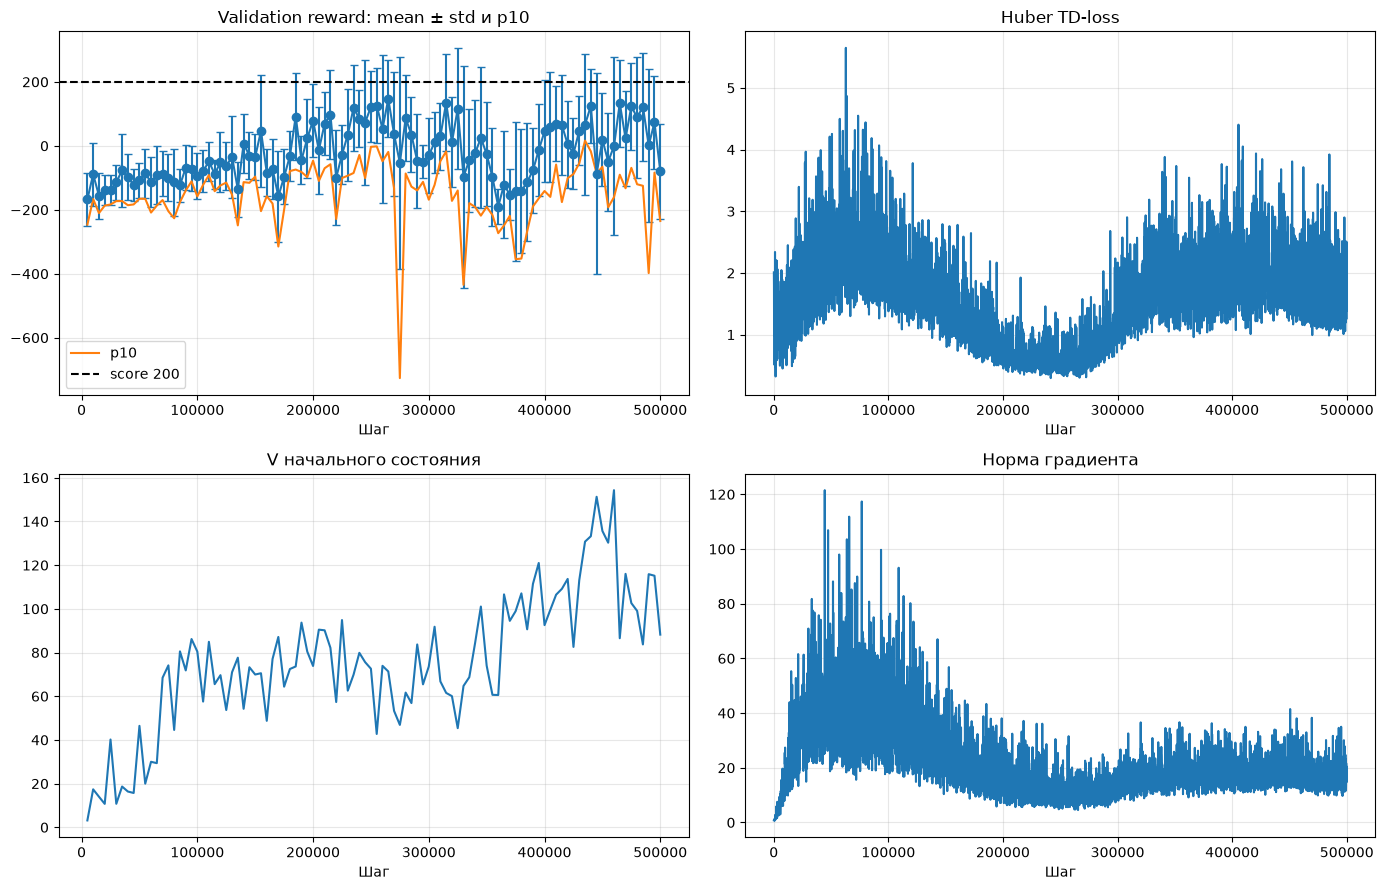

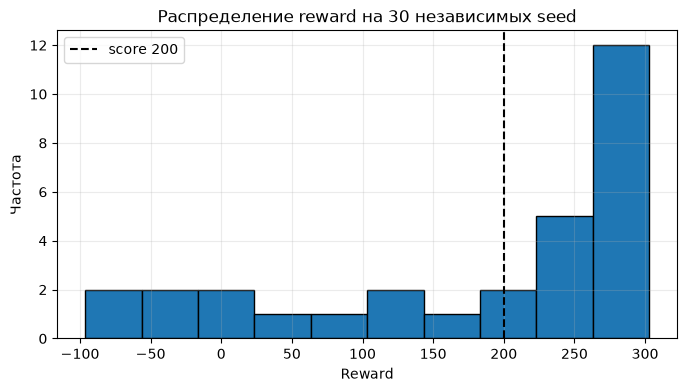

In [272]:


lunar_final_n_games = 30
lunar_final_seed = 42_000
lunar_score_threshold = 200.0


lunar_final_env = make_lunar_env()
lunar_final_scores = evaluate(
    lunar_final_env,
    lunar_agent_wind,
    n_games=lunar_final_n_games,
    greedy=True,
    t_max=LUNAR_MAX_EPISODE_STEPS,
    seed=lunar_final_seed,
    return_rewards=True,
)
lunar_final_env.close()
print(
    f"Финал: mean={lunar_final_scores.mean():.1f}, "
    f"std={lunar_final_scores.std():.1f}, "
    f"median={np.median(lunar_final_scores):.1f}, "
    f"p10={np.percentile(lunar_final_scores, 10):.1f}, "
    f"min={lunar_final_scores.min():.1f}, max={lunar_final_scores.max():.1f}"
)
print(
    f"Доля эпизодов >= {lunar_score_threshold:.0f}: "
    f"{(lunar_final_scores >= lunar_score_threshold).mean():.1%}"
)
if lunar_final_scores.mean() < lunar_score_threshold:
    print(
        "Порог 200 пока не достигнут: Run All продолжается, чтобы графики "
        "помогли диагностировать обучение. Баллы за устойчивое решение требуют "
        "mean >= 200 на этих независимых seed."
    )


fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes[0, 0].errorbar(
    lunar_eval_steps, lunar_rewards, yerr=lunar_reward_stds,
    marker="o", capsize=3,
)
axes[0, 0].plot(lunar_eval_steps, lunar_reward_p10, label="p10")
axes[0, 0].axhline(200, color="black", linestyle="--", label="score 200")
axes[0, 0].set(title="Validation reward: mean ± std и p10", xlabel="Шаг")
axes[0, 0].legend()
axes[0, 1].plot(lunar_loss_steps, lunar_losses)
axes[0, 1].set(title="Huber TD-loss", xlabel="Шаг")
axes[1, 0].plot(lunar_eval_steps, lunar_initial_values)
axes[1, 0].set(title="V начального состояния", xlabel="Шаг")
axes[1, 1].plot(lunar_loss_steps, lunar_grad_norms)
axes[1, 1].set(title="Норма градиента", xlabel="Шаг")
for ax in axes.flat:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
plt.close(fig)

plt.figure(figsize=(8, 4))
plt.hist(lunar_final_scores, bins=10, edgecolor="black")
plt.axvline(200, color="black", linestyle="--", label="score 200")
plt.title("Распределение reward на 30 независимых seed")
plt.xlabel("Reward")
plt.ylabel("Частота")
plt.grid(alpha=0.25)
plt.legend()
plt.show()



Агент без ветра Эпизод 1: return=241.24, шагов=192
Агент с ветром Эпизод 1: return=27.34, шагов=130
Агент без ветра Эпизод 2: return=235.57, шагов=293
Агент с ветром Эпизод 2: return=226.87, шагов=242
Агент без ветра Эпизод 3: return=266.16, шагов=190
Агент с ветром Эпизод 3: return=255.89, шагов=181
Агент без ветра Эпизод 4: return=289.81, шагов=233
Агент с ветром Эпизод 4: return=256.55, шагов=346
Агент без ветра Эпизод 5: return=213.56, шагов=297
Агент с ветром Эпизод 5: return=218.21, шагов=255


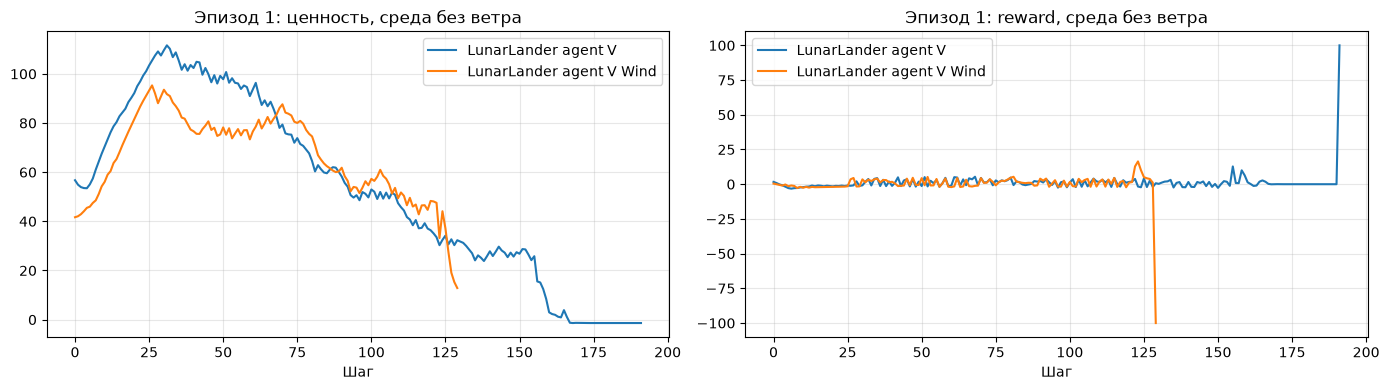

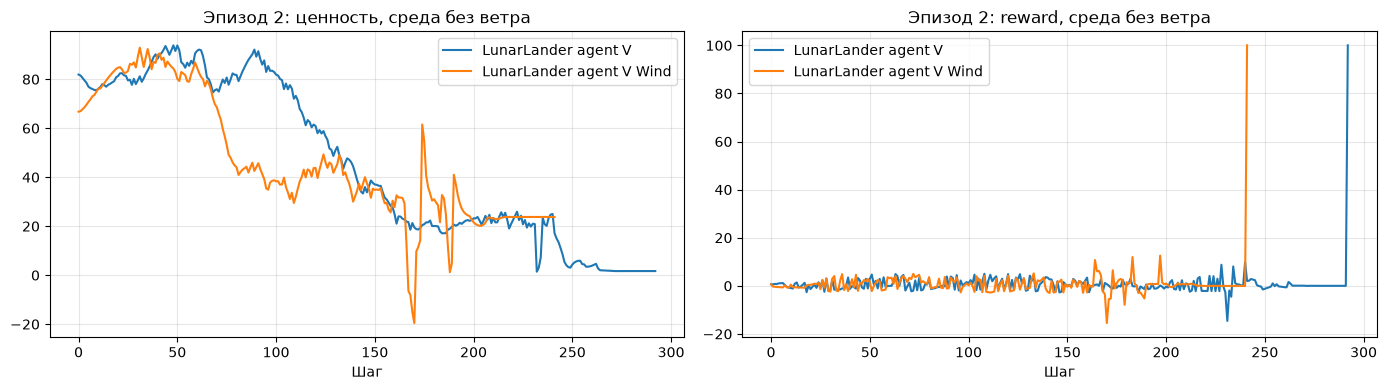

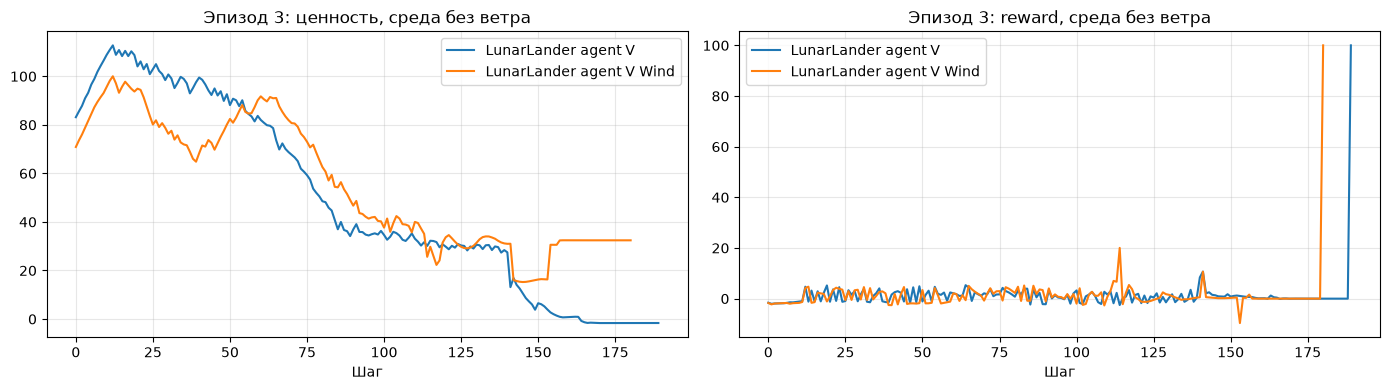

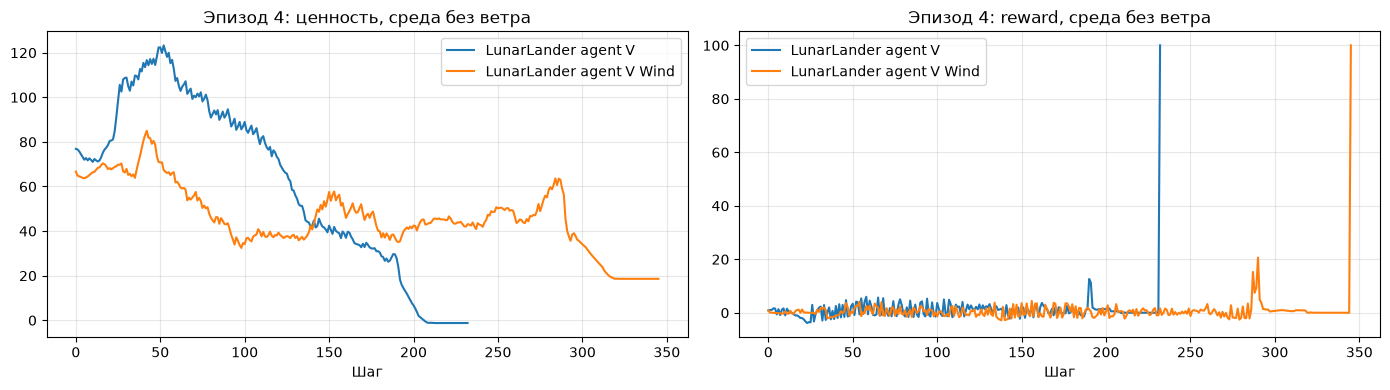

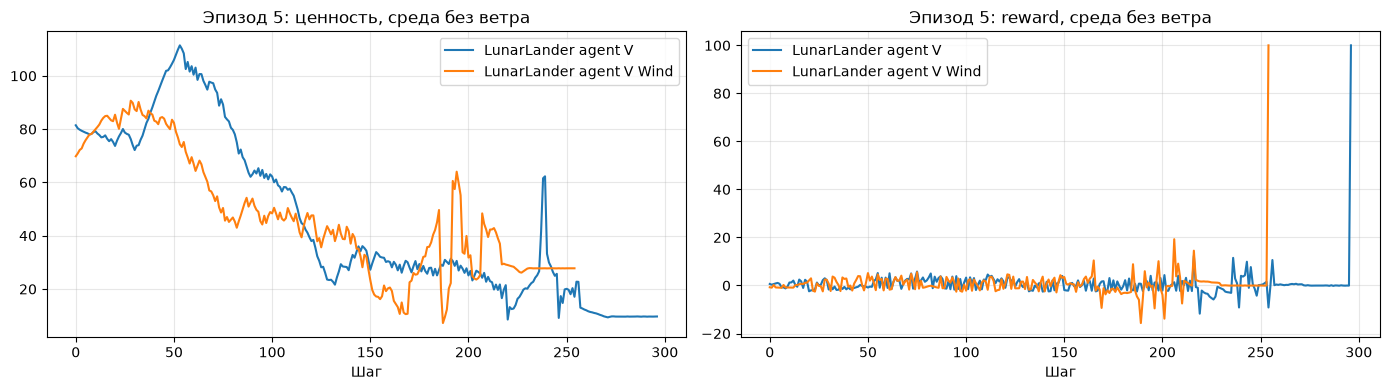

In [273]:

# %%

lunar_analysis_n_episodes = 5
lunar_analysis_seed = 250_001
lunar_gamma = 0.99

lunar_records_agent_wind_env_no_wind=[]
lunar_records_agent_no_wind_env_no_wind = []
lunar_analysis_env = make_lunar_env()
for episode_idx in range(lunar_analysis_n_episodes):
    record,record_wind = play_and_log_episode_both(
        lunar_analysis_env,
        lunar_agent,
        lunar_agent_wind,
        seed=lunar_analysis_seed + episode_idx,
        max_steps=LUNAR_MAX_EPISODE_STEPS,
    )
    lunar_records_agent_no_wind_env_no_wind.append(record)
    lunar_records_agent_wind_env_no_wind.append(record_wind)
    print(
        f"Агент без ветра Эпизод {episode_idx + 1}: return={record['rewards'].sum():.2f}, "
        f"шагов={len(record['rewards'])}"
    )
    print(
            f"Агент с ветром Эпизод {episode_idx + 1}: return={record_wind['rewards'].sum():.2f}, "
            f"шагов={len(record_wind['rewards'])}"
        )
lunar_analysis_env.close()

assert len(lunar_records_agent_no_wind_env_no_wind) == len(lunar_records_agent_wind_env_no_wind),  "число эпизодов должно совпадать для попарного сравнения"

#     Key in lunar_records      "states", "qvalues", "actions", "rewards", "next_states",
#            "terminated", "truncated",
n_episod=len(lunar_records_agent_no_wind_env_no_wind)

#for episode_idx, record in enumerate(lunar_records, start=1):
#    for episode_idx_wind, record_wind in enumerate(lunar_records_wind, start=1):
for episode_idx in range(n_episod):
        #mc_return = get_discounted_returns(record["rewards"], lunar_gamma)
        record=lunar_records_agent_no_wind_env_no_wind[episode_idx]
        record_wind=lunar_records_agent_wind_env_no_wind[episode_idx]
        
        values = record["qvalues"].max(axis=1)
        values_wind=record_wind['qvalues'].max(axis=1)
        fig, axes = plt.subplots(1, 2, figsize=(14, 4))
        axes[0].plot(values, label="LunarLander agent V")
        axes[0].plot(values_wind, label="LunarLander agent V Wind")
        
        axes[0].set(title=f"Эпизод {episode_idx+1}: ценность, cреда без ветра", xlabel="Шаг")
        axes[0].legend()
        axes[1].plot(record["rewards"],label="LunarLander agent V")
        axes[1].plot(record_wind['rewards'],label="LunarLander agent V Wind")
        axes[1].legend()
        axes[1].set(title=f"Эпизод {episode_idx+1}: reward, cреда без ветра", xlabel="Шаг")
        for ax in axes:
            ax.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()
        plt.close(fig)






# Экспиремент, проверяем влияние шумов на агентов обученных с разным условием по шуму.

Берём 50 эпизодов на каждую величину ветра(шума)

In [281]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm


WIND_POWERS = [0, 5, 10, 15, 20]

ANALYSIS_SEED = 250_001
 
N_EPISODES=50 # При каждой сил ветре будет сыграно 50 эпизодов каждым агентом

dict_mean_std_agent_no_wind={}
dict_mean_std_reward_agent_wind={}

lunar_records_agent_wind=[]
lunar_records_agent_no_wind = []
for wp in WIND_POWERS:
    temple_rewards_agent_wind=[]
    temple_rewards_agent=[]
    temple_rewards_std_agent_wind=[]
    temple_rewards_std_agent=[]
    if wp==0:
        lunar_analysis_env=make_lunar_env()
    else:
        lunar_analysis_env = make_lunar_env_wind(wind_power=wp)
    for episode_idx in range(N_EPISODES):
        record,record_wind = play_and_log_episode_both(
            lunar_analysis_env,
            lunar_agent,
            lunar_agent_wind,
            seed=lunar_analysis_seed + episode_idx,
            max_steps=LUNAR_MAX_EPISODE_STEPS,
        )
        lunar_records_agent_no_wind.append(record)
        lunar_records_agent_wind.append(record_wind)
        print(
            f"Cила ветра {wp}. Агент без ветра Эпизод {episode_idx + 1}: return={record['rewards'].sum():.2f}, "
            f"шагов={len(record['rewards'])}"
        )
        
        print(
                f"Cила ветра {wp}.Агент с ветром Эпизод {episode_idx + 1}: return={record_wind['rewards'].sum():.2f}, "
                f"шагов={len(record_wind['rewards'])}"
            )
        temple_rewards_agent_wind.append(record_wind['rewards'].sum())
        temple_rewards_agent.append(record['rewards'].sum())

    dict_mean_std_reward_agent_wind[wp]=[np.array(temple_rewards_agent_wind).mean(),np.array(temple_rewards_agent_wind).std()]
    dict_mean_std_agent_no_wind[wp]=[np.array(temple_rewards_agent).mean(),np.array(temple_rewards_agent).std()]
    lunar_analysis_env.close()




Cила ветра 0. Агент без ветра Эпизод 1: return=241.24, шагов=192
Cила ветра 0.Агент с ветром Эпизод 1: return=27.34, шагов=130
Cила ветра 0. Агент без ветра Эпизод 2: return=235.57, шагов=293
Cила ветра 0.Агент с ветром Эпизод 2: return=226.87, шагов=242
Cила ветра 0. Агент без ветра Эпизод 3: return=266.16, шагов=190
Cила ветра 0.Агент с ветром Эпизод 3: return=255.89, шагов=181
Cила ветра 0. Агент без ветра Эпизод 4: return=289.81, шагов=233
Cила ветра 0.Агент с ветром Эпизод 4: return=256.55, шагов=346
Cила ветра 0. Агент без ветра Эпизод 5: return=213.56, шагов=297
Cила ветра 0.Агент с ветром Эпизод 5: return=218.21, шагов=255
Cила ветра 0. Агент без ветра Эпизод 6: return=247.78, шагов=287
Cила ветра 0.Агент с ветром Эпизод 6: return=231.57, шагов=291
Cила ветра 0. Агент без ветра Эпизод 7: return=259.46, шагов=167
Cила ветра 0.Агент с ветром Эпизод 7: return=272.43, шагов=213
Cила ветра 0. Агент без ветра Эпизод 8: return=268.45, шагов=194
Cила ветра 0.Агент с ветром Эпизод 8: re

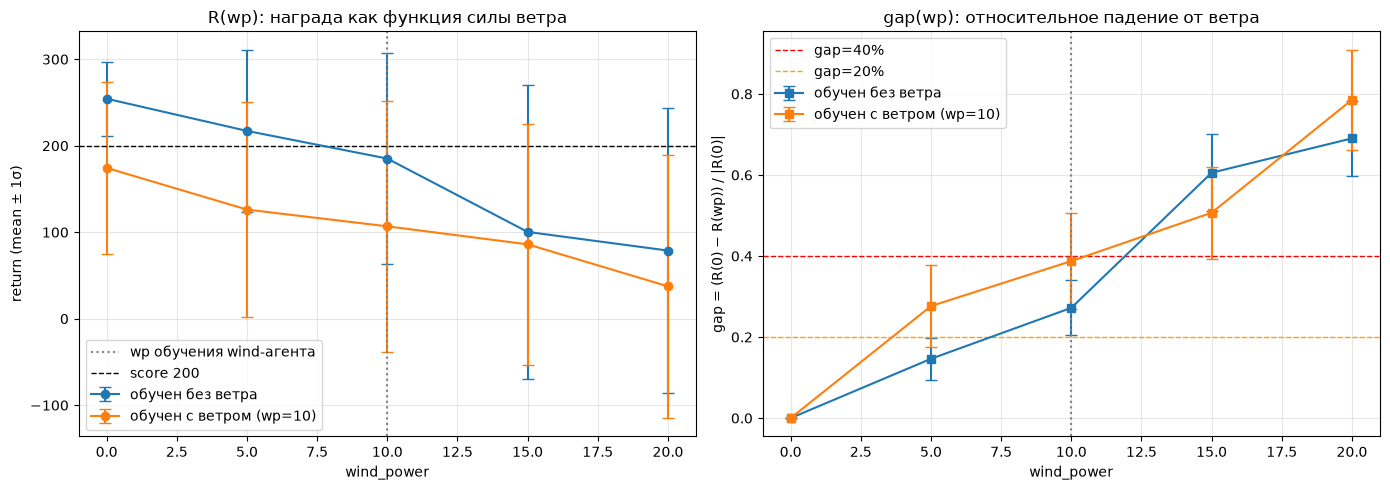

In [284]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- R(wp) ---
ax = axes[0]
for d, label, color in [
    (dict_mean_std_agent_no_wind, "обучен без ветра", "tab:blue"),
    (dict_mean_std_reward_agent_wind, "обучен с ветром (wp=10)", "tab:orange"),
]:
    means = [d[wp][0] for wp in WIND_POWERS]
    stds = [d[wp][1] for wp in WIND_POWERS]
    ax.errorbar(WIND_POWERS, means, yerr=stds, marker="o", capsize=4,
                label=label, color=color)
ax.axvline(10, color="gray", linestyle=":", label="wp обучения wind-агента")
ax.axhline(200, color="black", linestyle="--", linewidth=1, label="score 200")
ax.set(xlabel="wind_power", ylabel="return (mean ± 1σ)",
       title="R(wp): награда как функция силы ветра")
ax.grid(alpha=0.3)
ax.legend()

# --- gap(wp) без bootstrap: ошибка через propagation ---
ax = axes[1]
for d, label, color in [
    (dict_mean_std_agent_no_wind, "обучен без ветра", "tab:blue"),
    (dict_mean_std_reward_agent_wind, "обучен с ветром (wp=10)", "tab:orange"),
]:
    r0_mean = d[0][0]
    gaps, errs = [], []
    for wp in WIND_POWERS:
        if wp == 0:
            gaps.append(0.0)
            errs.append(0.0)
            continue
        m, s = d[wp]
        gap = (r0_mean - m) / abs(r0_mean)
        # грубая ошибка: SE_gap ≈ s / (sqrt(N) * |r0|)  (только от R(wp))
        errs.append(s / np.sqrt(N_EPISODES) / abs(r0_mean))
        gaps.append(gap)
    ax.errorbar(WIND_POWERS, gaps, yerr=errs, marker="s", capsize=4,
                label=label, color=color)
ax.axhline(0.4, color="red", linestyle="--", linewidth=1, label="gap=40%")
ax.axhline(0.2, color="orange", linestyle="--", linewidth=1, label="gap=20%")
ax.axvline(10, color="gray", linestyle=":")
ax.set(xlabel="wind_power", ylabel="gap = (R(0) − R(wp)) / |R(0)|",
       title="gap(wp): относительное падение от ветра")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [287]:
for key in  dict_mean_std_agent_no_wind.keys():
    if key==0:
        continue
    R_calm_base = dict_mean_std_agent_no_wind[0][0]
    R_wind_base = dict_mean_std_agent_no_wind[key][0]
    R_calm_wind = dict_mean_std_reward_agent_wind[0][0]
    R_wind_wind = dict_mean_std_reward_agent_wind[key][0]

    gap_base = (R_calm_base - R_wind_base) / abs(R_calm_base)
    gap_wind = (R_calm_wind - R_wind_wind) / abs(R_calm_wind)
    print(f"Cила ветра {key}")
    print(f"База:  R_calm={R_calm_base:.1f}, R_wind={R_wind_base:.1f}, gap={gap_base:.1%}")
    print(f"Ветер: R_calm={R_calm_wind:.1f}, R_wind={R_wind_wind:.1f}, gap={gap_wind:.1%}")
    verdict = "ПОДТВЕРЖДЕНА" if gap_base > 0.4 and gap_wind < 0.2 else "НЕ ПОДТВЕРЖДЕНА"
    print(f"Гипотеза: {verdict}")

Cила ветра 5
База:  R_calm=254.3, R_wind=217.1, gap=14.6%
Ветер: R_calm=174.3, R_wind=126.1, gap=27.6%
Гипотеза: НЕ ПОДТВЕРЖДЕНА
Cила ветра 10
База:  R_calm=254.3, R_wind=185.1, gap=27.2%
Ветер: R_calm=174.3, R_wind=106.8, gap=38.7%
Гипотеза: НЕ ПОДТВЕРЖДЕНА
Cила ветра 15
База:  R_calm=254.3, R_wind=100.3, gap=60.5%
Ветер: R_calm=174.3, R_wind=86.0, gap=50.7%
Гипотеза: НЕ ПОДТВЕРЖДЕНА
Cила ветра 20
База:  R_calm=254.3, R_wind=78.8, gap=69.0%
Ветер: R_calm=174.3, R_wind=37.4, gap=78.5%
Гипотеза: НЕ ПОДТВЕРЖДЕНА


# Вывод по экспериментальному исследованию

1. Цель и постановка

Исследовательский вопрос. При фиксированном бюджете взаимодействий (500 000 шагов) зависит ли величина падения качества RL-агента при оценке в условиях ветра (не встречавшегося при обучении) от того, подвергался ли агент ветру во время обучения?

Гипотеза. Базовое условие (обучение без ветра) при оценке с ветром падает более чем на 40% относительно оценки без ветра. Экспериментальное условие (обучение с ветром при wp=10, тот же бюджет и гиперпараметры) при той же оценке падает менее чем на 20%. Причина: обучение с ветром вынуждает политику выучить компенсаторные действия и стать устойчивой к возмущениям динамики; политика без ветра опирается на детерминированную динамику, и боковая сила ломает отслеживание траектории.

Метрика. gap(wp) = (R_calm − R_wind(wp)) / |R_calm|, где R_calm — средняя награда при enable_wind=False (50 эпизодов), R_wind(wp) — средняя награда при enable_wind=True, wind_power ∈ {0, 5, 10, 15, 20} (по 50 эпизодов на каждую силу).

План сравнения. Меняется ровно один фактор — наличие ветра при обучении. Алгоритм (Dueling DQN), бюджет (500k), seed (42), процедура оценки и гиперпараметры (lr=1e-3, decay=60k, batch=256, Huber, Double DQN, hard target update каждые 1000 шагов) идентичны у обоих агентов.

*Финальное качество в среде без ветра*

|Агент|	mean|	std|	median	|p10|	min|	max|	доля ≥ 200|
|---|---|---|---|---|---|---|---|
|Без ветра|	264.1	|32.4	|269.4|	232.2|	181.1|	316.3|	93.3%|
|С ветром (wp=10)|	174.7|	125.1|	250.7|	−19.4| −96.2 |	302.8	|60.0%|

Относительное падение gap
```
Cила ветра 5
База:  R_calm=254.3, R_wind=217.1, gap=14.6%
Ветер: R_calm=174.3, R_wind=126.1, gap=27.6%
Гипотеза: НЕ ПОДТВЕРЖДЕНА
Cила ветра 10
База:  R_calm=254.3, R_wind=185.1, gap=27.2%
Ветер: R_calm=174.3, R_wind=106.8, gap=38.7%
Гипотеза: НЕ ПОДТВЕРЖДЕНА
Cила ветра 15
База:  R_calm=254.3, R_wind=100.3, gap=60.5%
Ветер: R_calm=174.3, R_wind=86.0, gap=50.7%
Гипотеза: НЕ ПОДТВЕРЖДЕНА
Cила ветра 20
База:  R_calm=254.3, R_wind=78.8, gap=69.0%
Ветер: R_calm=174.3, R_wind=37.4, gap=78.5%
Гипотеза: НЕ ПОДТВЕРЖДЕНА
```

**3. Проверка гипотезы**

Критерий гипотезы: gap_base > 40% и gap_wind < 20% при wp = 10 (тот же ветер, что при обучении wind-агента).

Фактические значения:

gap_base(10) = 27.2% — не превышает 40%;

gap_wind(10) = 38.7% — превышает 20%.

Гипотеза в исходной формулировке не подтверждена. Более того, направление эффекта обратное ожидаемому: wind-агент падает сильнее базового (38.7% против 27.2%), а не слабее.

### Заключение
При фиксированном бюджете 500 000 шагов и выбранных гиперпараметрах гипотеза о повышенной устойчивости агента, обученного с ветром, не подтверждена: gap_base(10) = 27.2% (< 40%) и gap_wind(10) = 38.7% (> 20%). Основная причина — несостоятельность wind-агента: он не сходится даже в спокойной среде (R_calm = 174 < 200), и его больший gap отражает общую слабость политики, а не отсутствие компенсаторных навыков. Направление эффекта при более сильном ветре (wp=15: 50.7% у wind-агента против 60.5% у базового) не противоречит идее о компенсаторных навыках, но этот результат получен при оценке в ветре, более сильном, чем при обучении, и требует отдельной симметричной проверки.

Полученный результат — валидный отрицательный результат, указывающий на границу применимости выбранных гиперпараметров: при wp=10 и бюджете 500k экспериментальное условие выходит за пределы обучаемости. Для корректной проверки гипотезы необходимо либо снизить wp до 5, либо симметрично стабилизировать обучение обоих агентов (soft target, меньший lr, больший decay), либо переформулировать критерий в терминах направления (gap_wind < gap_base при том же wp), а не абсолютных порогов 40%/20%.

